# ผู้เสียชีวิตจากอุบัติเหตุทางถนนในกรุงเทพมหานคร พ.ศ. 2554–2569

วิเคราะห์ข้อมูลเปิดภาครัฐจากระบบบูรณาการข้อมูลการตายจากอุบัติเหตุทางถนน (3 ฐาน) ของกรมควบคุมโรค
เผยแพร่ผ่าน [data.go.th](https://data.go.th/dataset/rtddi) — รวม 16 ปี เฉพาะผู้ที่เสียชีวิตในกรุงเทพฯ

**คำถามที่ต้องการตอบ**

1. ตัวเลขผู้เสียชีวิตในกรุงเทพฯ ดีขึ้นหรือแย่ลงในรอบ 16 ปี
2. ยานพาหนะแบบไหนเกี่ยวข้องกับการเสียชีวิตมากที่สุด และสัดส่วนเปลี่ยนไปไหม
3. ใครคือผู้เสียชีวิต — อายุ เพศ และต่างกันตามประเภทยานพาหนะหรือไม่
4. เกิดเหตุช่วงเวลาไหนของวันและวันไหนของสัปดาห์
5. กระจุกตัวอยู่บริเวณใดของเมือง

**หมายเหตุสำคัญก่อนอ่าน** — ชุดข้อมูลนี้นับเฉพาะ*ผู้เสียชีวิต* ไม่ใช่จำนวนอุบัติเหตุหรือผู้บาดเจ็บ
และนับตาม*จังหวัดที่เสียชีวิต* ซึ่งอาจไม่ใช่จังหวัดที่เกิดเหตุเสมอไป ข้อมูลยังมีความไม่สมบูรณ์หลายจุด
ซึ่งจะตรวจสอบและจัดการอย่างละเอียดในหัวข้อที่ 2 และ 3 ก่อนวิเคราะห์

> ข้อมูลดิบดึงด้วย `python analysis/fetch_data.py` และ commit ไว้ที่ `analysis/data/` แล้ว
> notebook นี้จึงรันซ้ำได้โดยไม่ต้องต่ออินเทอร์เน็ต

## 1. ตั้งค่าและโหลดข้อมูล

In [1]:
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore")

# ฟอนต์ที่มีสระและวรรณยุกต์ไทย ไม่งั้นกราฟจะขึ้นเป็นกล่องสี่เหลี่ยม
available = {f.name for f in mpl.font_manager.fontManager.ttflist}
for candidate in ("Leelawadee UI", "Tahoma", "Noto Sans Thai", "Sarabun"):
    if candidate in available:
        mpl.rcParams["font.family"] = candidate
        break
mpl.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "figure.autolayout": True,
})

INK = "#2b2d42"
ACCENT = "#e63946"
MUTED = "#8d99ae"
PALETTE = ["#e63946", "#457b9d", "#f4a261", "#2a9d8f", "#8d99ae", "#9b5de5", "#c9ada7"]

raw = pd.read_csv(Path("data") / "bangkok-road-deaths.csv", encoding="utf-8-sig")
print(f"โหลดข้อมูล {len(raw):,} แถว  {raw.shape[1]} คอลัมน์")
raw.head(3)

โหลดข้อมูล 12,146 แถว  16 คอลัมน์


,year_th,dead_date,age,sex,nationality,home_district,acc_district,acc_subdistrict,vehicle,helmet,seatbelt,icd10,lat,lng,rec_date,rec_time
0,2569,2026-02-09T00:00:00,51.0,ชาย,NaN,คลองเตย,เขตบางกะปิ,หัวหมาก,รถจักรยานยนต์,NaN,NaN,Y349,NaN,NaN,NaN,NaN
1,2569,2026-02-14T00:00:00,33.0,ชาย,NaN,ธัญบุรี,เขตสายไหม,คลองถนน,รถจักรยานยนต์,NaN,NaN,V892,100.622532,13.919365,NaN,NaN
2,2569,2026-02-07T00:00:00,25.0,ชาย,NaN,NaN,เขตวังทองหลาง,พลับพลา,รถจักรยานยนต์,NaN,NaN,Y349,NaN,NaN,NaN,NaN


## 2. สำรวจคุณภาพข้อมูลก่อน

ขั้นตอนนี้สำคัญที่สุดและมักถูกข้าม ข้อมูลเปิดภาครัฐแทบไม่เคยพร้อมใช้ทันที
ถ้าวิเคราะห์เลยโดยไม่ดูว่าคอลัมน์ไหนกรอกจริงบ้าง ข้อสรุปที่ได้จะผิดโดยไม่รู้ตัว

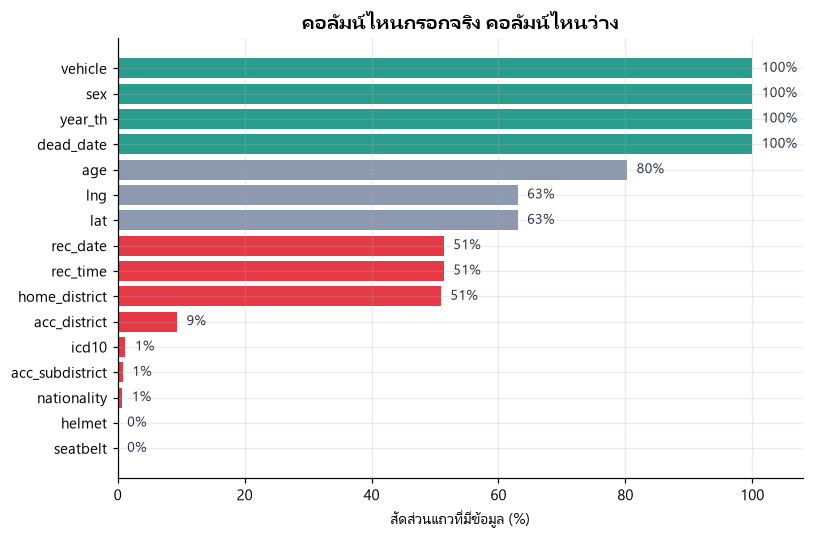

คอลัมน์ที่ใช้ไม่ได้เลย: seatbelt, helmet


In [2]:
fill = raw.notna().mean().mul(100).sort_values()
# ช่องว่างในไฟล์นี้มีทั้งค่าว่างและ NaN นับใหม่ให้ตรงความจริง
fill = (raw.replace("", np.nan).notna().mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(7.5, 5))
colors = [ACCENT if v < 60 else (MUTED if v < 95 else "#2a9d8f") for v in fill]
ax.barh(fill.index, fill.values, color=colors)
for y, v in enumerate(fill.values):
    ax.text(v + 1.5, y, f"{v:.0f}%", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 108)
ax.set_xlabel("สัดส่วนแถวที่มีข้อมูล (%)")
ax.set_title("คอลัมน์ไหนกรอกจริง คอลัมน์ไหนว่าง")
plt.show()

print("คอลัมน์ที่ใช้ไม่ได้เลย:", ", ".join(fill[fill == 0].index) or "ไม่มี")

ผลออกมาชัดเจนว่ามีสามกลุ่ม

- **ใช้ได้เต็มที่** — ปี วันที่เสียชีวิต เพศ ประเภทยานพาหนะ
- **ใช้ได้แต่ต้องระวัง** — อายุ พิกัด เวลาที่บันทึก เขตที่พักอาศัย (กรอกราว 50–80%)
- **ใช้ไม่ได้** — หมวกกันน็อกและเข็มขัดนิรภัยว่างทั้ง 12,146 แถว

กรณีหมวกกันน็อกน่าเสียดายที่สุด เพราะเป็นปัจจัยเสี่ยงที่ตรงประเด็นที่สุดสำหรับเมืองที่
ผู้เสียชีวิตส่วนใหญ่เป็นผู้ใช้มอเตอร์ไซค์ แต่เมื่อไม่มีข้อมูลก็ต้องยอมรับและตัดทิ้ง
ไม่ใช่เดาแทน

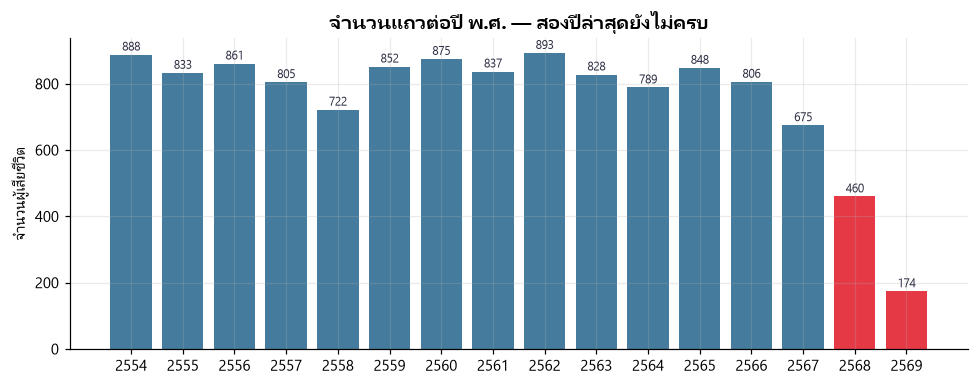

วันที่ล่าสุดของแต่ละปี (3 ปีท้าย):
  2567: 31 Dec 2024
  2568: 30 Sep 2025
  2569: 31 Mar 2026


In [3]:
per_year = raw.groupby("year_th").size()
last_date = raw.assign(d=pd.to_datetime(raw["dead_date"], errors="coerce")).groupby("year_th")["d"].max()

fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [ACCENT if y >= 2568 else "#457b9d" for y in per_year.index]
ax.bar(per_year.index.astype(str), per_year.values, color=colors)
ax.set_title("จำนวนแถวต่อปี พ.ศ. — สองปีล่าสุดยังไม่ครบ")
ax.set_ylabel("จำนวนผู้เสียชีวิต")
for x, v in zip(range(len(per_year)), per_year.values):
    ax.text(x, v + 12, f"{v}", ha="center", fontsize=8, color=INK)
plt.show()

print("วันที่ล่าสุดของแต่ละปี (3 ปีท้าย):")
for year, date in last_date.tail(3).items():
    print(f"  {year}: {date:%d %b %Y}")

**เจอปัญหาแรกที่ต้องจัดการ** ปี 2568 มี 460 ราย และ 2569 มีแค่ 174 ราย เทียบกับปีก่อนหน้าที่อยู่ราว 800
ไม่ใช่เพราะถนนปลอดภัยขึ้นอย่างน่าอัศจรรย์ แต่เพราะ**ข้อมูลยังทยอยเข้า** ดูจากวันที่ล่าสุดของแต่ละปีก็ยืนยันได้

ถ้าเอาสองปีนี้ไปรวมในกราฟแนวโน้มจะเห็นเป็นขาลงดิ่งซึ่งเป็นภาพลวง
การวิเคราะห์แนวโน้มด้านล่างจึงตัดปีที่ยังไม่สมบูรณ์ออก

In [4]:
num_age = pd.to_numeric(raw["age"], errors="coerce")
lat = pd.to_numeric(raw["lat"], errors="coerce")
lng = pd.to_numeric(raw["lng"], errors="coerce")

print("อายุ      : ต่ำสุด", num_age.min(), " สูงสุด", num_age.max(), f" (เกิน 110 ปี: {(num_age > 110).sum()} แถว)")
print("ละติจูด   : ", round(lat.min(), 3), "ถึง", round(lat.max(), 3))
print("ลองจิจูด  : ", round(lng.min(), 3), "ถึง", round(lng.max(), 3))
print()
print("กรุงเทพฯ อยู่ราวละติจูด 13.5–14.0 และลองจิจูด 100.3–100.9 — ค่าที่เกินช่วงนี้มีปัญหาแน่นอน")
print(f"  พิกัดเป็นศูนย์ทั้งคู่      : {((lat == 0) & (lng == 0)).sum():5d} แถว")
print(f"  ละติจูดเกิน 90 (เป็นไปไม่ได้) : {(lat > 90).sum():5d} แถว  ← น่าจะสลับคอลัมน์กับลองจิจูด")

อายุ      : ต่ำสุด 0.0  สูงสุด 149.0  (เกิน 110 ปี: 31 แถว)
ละติจูด   :  -0.077 ถึง 100.935
ลองจิจูด  :  0.0 ถึง 105.295

กรุงเทพฯ อยู่ราวละติจูด 13.5–14.0 และลองจิจูด 100.3–100.9 — ค่าที่เกินช่วงนี้มีปัญหาแน่นอน
  พิกัดเป็นศูนย์ทั้งคู่      :     2 แถว
  ละติจูดเกิน 90 (เป็นไปไม่ได้) :   479 แถว  ← น่าจะสลับคอลัมน์กับลองจิจูด


**เจอปัญหาที่สองและสาม**

- มีแถวที่อายุมากกว่า 110 ปี รวมถึงค่าสูงสุด 149 ปี ซึ่งเป็นไปไม่ได้
- มีแถวที่ละติจูดเกิน 90 องศา ซึ่งผิดนิยามของพิกัดภูมิศาสตร์ — ค่าพวกนี้อยู่ในช่วง 100 กว่า ๆ
  ซึ่งพอดีกับช่วงลองจิจูดของไทย แปลว่า**กรอกสลับคอลัมน์กัน** ไม่ใช่ข้อมูลขยะที่ต้องทิ้ง แค่สลับกลับก็ใช้ได้
- มีแถวที่พิกัดเป็น 0,0 ซึ่งคือ "ไม่มีข้อมูล" ที่ถูกบันทึกเป็นเลขศูนย์ ถ้าไม่ตัดออกจุดจะไปโผล่กลางมหาสมุทรแอตแลนติก

## 3. ทำความสะอาดข้อมูล

ทุกกฎด้านล่างนับจำนวนแถวที่ได้รับผลกระทบไว้ด้วย เพื่อให้ตรวจสอบย้อนกลับได้ว่า
ตัดอะไรทิ้งไปเท่าไร ไม่ใช่ทำความสะอาดแบบเงียบ ๆ

In [5]:
df = raw.copy()

# วันที่และเวลา ─ rec_time เก็บเป็น timestamp ปลอมปี 1900 ใช้ได้แค่ส่วนเวลา
df["date"] = pd.to_datetime(df["dead_date"], errors="coerce")
df["year"] = df["date"].dt.year              # ค.ศ.
df["month"] = df["date"].dt.month
df["dow"] = df["date"].dt.day_of_week          # 0 = จันทร์
df["hour"] = pd.to_datetime(df["rec_time"], errors="coerce").dt.hour

# อายุ ─ เก็บเฉพาะช่วงที่เป็นไปได้
age = pd.to_numeric(df["age"], errors="coerce")
bad_age = ((age > 110) | (age < 0)).sum()
df["age_clean"] = age.where((age >= 0) & (age <= 110))

# พิกัด ─ สลับกลับก่อน แล้วค่อยตัดที่อยู่นอกกรอบกรุงเทพฯ
lat = pd.to_numeric(df["lat"], errors="coerce")
lng = pd.to_numeric(df["lng"], errors="coerce")
swapped = (lat > 90) & (lng < 90)
n_swapped = swapped.sum()
lat2 = lat.where(~swapped, lng)
lng2 = lng.where(~swapped, lat)

zeros = ((lat2 == 0) | (lng2 == 0)).sum()
in_bkk = lat2.between(13.4, 14.0) & lng2.between(100.2, 100.95)
df["lat_clean"] = lat2.where(in_bkk)
df["lng_clean"] = lng2.where(in_bkk)

# ยานพาหนะ ─ แยกให้ชัดว่า "ไม่ระบุ" ไม่ใช่ประเภทหนึ่ง แต่คือข้อมูลที่หายไป
df["vehicle_known"] = df["vehicle"].ne("ไม่ระบุพาหนะ")
df["sex_known"] = df["sex"].ne("ไม่ระบุ")

print(f"อายุผิดปกติที่ตัดออก        : {bad_age:6,} แถว")
print(f"พิกัดที่สลับ lat/lng แล้วแก้คืน : {n_swapped:6,} แถว")
print(f"พิกัดที่เป็นศูนย์             : {zeros:6,} แถว")
print(f"พิกัดที่ใช้ได้หลังทำความสะอาด   : {df['lat_clean'].notna().sum():6,} แถว "
      f"({df['lat_clean'].notna().mean():.0%} ของทั้งหมด)")
print(f"ระบุประเภทยานพาหนะได้        : {df['vehicle_known'].sum():6,} แถว "
      f"({df['vehicle_known'].mean():.0%})")
print(f"มีเวลาเกิดเหตุ               : {df['hour'].notna().sum():6,} แถว "
      f"({df['hour'].notna().mean():.0%})")

อายุผิดปกติที่ตัดออก        :     31 แถว
พิกัดที่สลับ lat/lng แล้วแก้คืน :    479 แถว
พิกัดที่เป็นศูนย์             :      2 แถว
พิกัดที่ใช้ได้หลังทำความสะอาด   :  7,529 แถว (62% ของทั้งหมด)
ระบุประเภทยานพาหนะได้        :  5,818 แถว (48%)
มีเวลาเกิดเหตุ               :  6,243 แถว (51%)


In [6]:
# ปีที่ข้อมูลยังไม่สมบูรณ์ ใช้ไม่ได้กับการดูแนวโน้ม
INCOMPLETE_TH = [2568, 2569]
complete = df[~df["year_th"].isin(INCOMPLETE_TH)].copy()

print(f"ชุดข้อมูลเต็ม          : {len(df):,} แถว (ใช้กับการวิเคราะห์ที่ไม่เกี่ยวกับแนวโน้มเวลา)")
print(f"ชุดข้อมูลปีที่สมบูรณ์   : {len(complete):,} แถว  ปี พ.ศ. "
      f"{complete['year_th'].min()}–{complete['year_th'].max()}")

ชุดข้อมูลเต็ม          : 12,146 แถว (ใช้กับการวิเคราะห์ที่ไม่เกี่ยวกับแนวโน้มเวลา)
ชุดข้อมูลปีที่สมบูรณ์   : 11,512 แถว  ปี พ.ศ. 2554–2567


## 4. คำถามที่ 1 — ตัวเลขดีขึ้นหรือแย่ลง

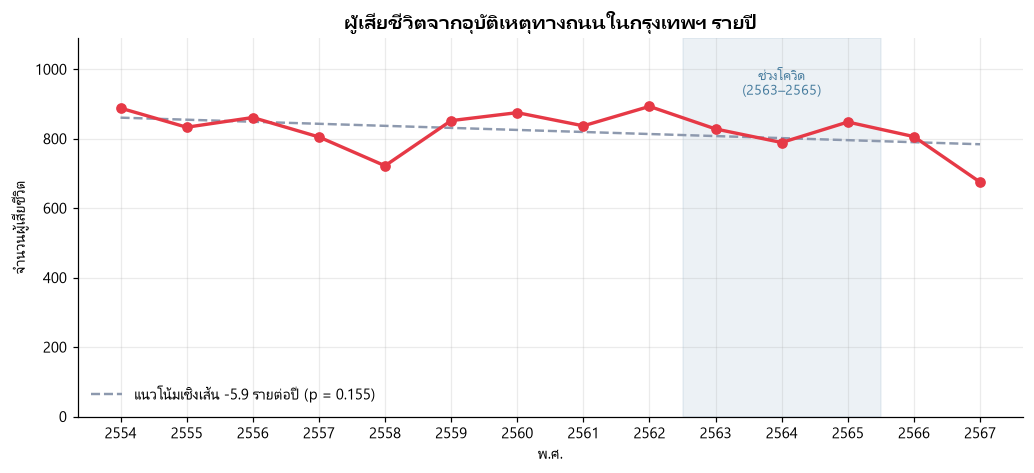

สูงสุด  : 893 ราย ในปี 2562
ล่าสุด  : 675 ราย ในปี 2567  (-24.4% จากจุดสูงสุด)
ค่าเฉลี่ย: 822 รายต่อปี (ส่วนเบี่ยงเบนมาตรฐาน 61) เท่ากับราว 2.3 รายต่อวัน

แนวโน้มเชิงเส้น : -5.9 รายต่อปี  p = 0.155  R² = 0.161
  p สูงกว่า 0.05 แปลว่ายังสรุปไม่ได้ว่าแนวโน้มขาลงนี้ต่างจากความผันผวนปกติ

ช่วงโควิด 2563–2565 : [828, 789, 848] เฉลี่ย 822
ก่อนโควิด 2554–2562 : เฉลี่ย 841


In [7]:
yearly = complete.groupby("year_th").size()
x = np.arange(len(yearly))
slope, intercept, r, p, se = stats.linregress(x, yearly.values)

fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.plot(yearly.index.astype(str), yearly.values, "-o", color=ACCENT, lw=2.2, ms=6, zorder=3)
ax.plot(yearly.index.astype(str), intercept + slope * x, "--", color=MUTED, lw=1.6,
        label=f"แนวโน้มเชิงเส้น {slope:+.1f} รายต่อปี (p = {p:.3f})")
ax.axvspan(8.5, 11.5, color="#457b9d", alpha=0.10, zorder=0)
ax.text(10.0, yearly.max() * 1.13, "ช่วงโควิด\n(2563–2565)", ha="center", va="top",
        fontsize=9, color="#457b9d")
ax.set_title("ผู้เสียชีวิตจากอุบัติเหตุทางถนนในกรุงเทพฯ รายปี")
ax.set_ylabel("จำนวนผู้เสียชีวิต")
ax.set_xlabel("พ.ศ.")
ax.set_ylim(0, yearly.max() * 1.22)
ax.legend(frameon=False, loc="lower left")
plt.show()

peak_year, peak = yearly.idxmax(), yearly.max()
last_year, last = yearly.index[-1], yearly.iloc[-1]
print(f"สูงสุด  : {peak} ราย ในปี {peak_year}")
print(f"ล่าสุด  : {last} ราย ในปี {last_year}  ({(last - peak) / peak:+.1%} จากจุดสูงสุด)")
print(f"ค่าเฉลี่ย: {yearly.mean():.0f} รายต่อปี (ส่วนเบี่ยงเบนมาตรฐาน {yearly.std():.0f}) "
      f"เท่ากับราว {yearly.mean() / 365:.1f} รายต่อวัน")
print()
print(f"แนวโน้มเชิงเส้น : {slope:+.1f} รายต่อปี  p = {p:.3f}  R² = {r**2:.3f}")
print("  p สูงกว่า 0.05 แปลว่ายังสรุปไม่ได้ว่าแนวโน้มขาลงนี้ต่างจากความผันผวนปกติ")
covid = yearly.loc[[2563, 2564, 2565]]
print()
print(f"ช่วงโควิด 2563–2565 : {list(covid)} เฉลี่ย {covid.mean():.0f}")
print(f"ก่อนโควิด 2554–2562 : เฉลี่ย {yearly.loc[2554:2562].mean():.0f}")

**ตัวเลขแทบไม่ขยับมา 14 ปี** แกว่งอยู่ราว 675–893 รายต่อปี ค่าเฉลี่ย 822 ราย
เส้นแนวโน้มลาดลงราว 6 รายต่อปี แต่ **p = 0.15 ซึ่งเกินเกณฑ์ 0.05** และอธิบายความผันผวนได้เพียง 16%
แปลว่ายังสรุปไม่ได้ว่านี่คือการลดลงจริง หรือเป็นเพียงความผันผวนปีต่อปีตามปกติ
การเขียนว่า "สถานการณ์ดีขึ้น" จากข้อมูลชุดนี้จึงยังเร็วเกินไป

ที่น่าประหลาดใจกว่าคือ **ไม่พบการลดลงในช่วงโควิดเลย** ปี 2563–2565 เฉลี่ย 822 ราย
เทียบกับช่วงก่อนหน้าที่ 841 ราย ต่างกันไม่ถึง 3% ทั้งที่เป็นช่วงล็อกดาวน์และการเดินทางลดลงอย่างมาก
ซึ่งต่างจากหลายประเทศที่ตัวเลขดิ่งลงชัดเจนในช่วงเดียวกัน

เป็นไปได้ว่าการเดินทางที่ยังเหลืออยู่ช่วงนั้นเสี่ยงกว่าเดิม เช่น ถนนโล่งทำให้ใช้ความเร็วสูงขึ้น
หรือสัดส่วนการเดินทางด้วยมอเตอร์ไซค์ส่งของเพิ่มขึ้น แต่**ข้อมูลชุดนี้พิสูจน์ไม่ได้** ต้องมีข้อมูล
ปริมาณการจราจรมาประกอบ จึงบันทึกไว้เป็นข้อสังเกตที่ควรตามต่อ ไม่ใช่ข้อสรุป

ปี 2567 ที่ 675 ราย เป็นค่าต่ำสุดในรอบ 14 ปี และต่ำกว่าจุดสูงสุดถึง 24% แต่เป็นเพียงปีเดียว
ต้องรอข้อมูลปี 2568–2569 เข้าครบก่อนจึงจะบอกได้ว่าเป็นจุดเริ่มของขาลงจริงหรือไม่

## 5. คำถามที่ 2 — ยานพาหนะแบบไหน

ก่อนตอบต้องจัดการปัญหาใหญ่ข้อหนึ่งก่อน

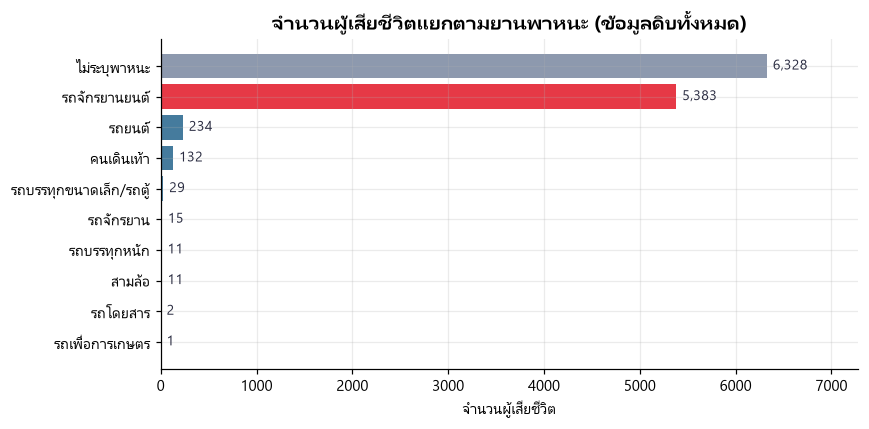

"ไม่ระบุพาหนะ" คิดเป็น 52.1% ของข้อมูลทั้งหมด — มากกว่าทุกประเภทที่ระบุได้รวมกัน


In [8]:
vc = df["vehicle"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
colors = [MUTED if name == "ไม่ระบุพาหนะ" else ACCENT if name == "รถจักรยานยนต์" else "#457b9d"
          for name in vc.index]
ax.barh(vc.index[::-1], vc.values[::-1], color=colors[::-1])
for y, v in enumerate(vc.values[::-1]):
    ax.text(v + 60, y, f"{v:,}", va="center", fontsize=9, color=INK)
ax.set_xlim(0, vc.max() * 1.15)
ax.set_title("จำนวนผู้เสียชีวิตแยกตามยานพาหนะ (ข้อมูลดิบทั้งหมด)")
ax.set_xlabel("จำนวนผู้เสียชีวิต")
plt.show()

unknown_share = (df["vehicle"] == "ไม่ระบุพาหนะ").mean()
print(f'"ไม่ระบุพาหนะ" คิดเป็น {unknown_share:.1%} ของข้อมูลทั้งหมด — มากกว่าทุกประเภทที่ระบุได้รวมกัน')

**ข้อนี้คือกับดักที่ต้องระวัง** ถ้ารายงานว่า "มอเตอร์ไซค์คิดเป็น 44% ของผู้เสียชีวิต" จะเข้าใจผิดทันที
เพราะตัวหารรวมแถวที่ไม่รู้ว่าเป็นพาหนะอะไรไปด้วย

วิธีที่ถูกต้องคือคิดสัดส่วนจาก**เฉพาะแถวที่ระบุได้** แล้วบอกให้ชัดว่าตัวหารคืออะไร
พร้อมตรวจก่อนว่าการที่ข้อมูลหายไปนั้นสุ่มหรือมีรูปแบบ เพราะถ้าไม่สุ่มสัดส่วนที่คำนวณจะเอนเอียง

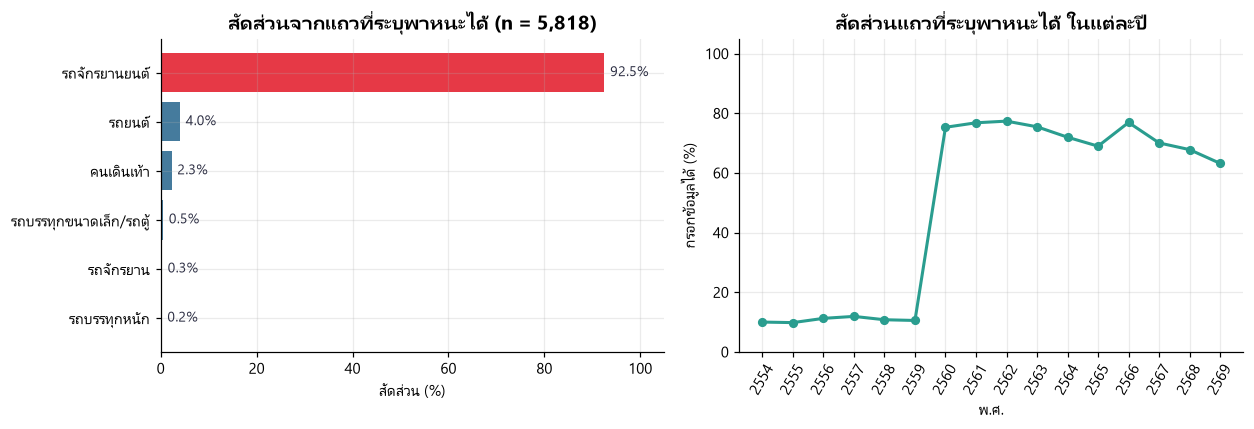

มอเตอร์ไซค์: 5,383 จาก 5,818 ราย = 92.5%
ช่วงความเชื่อมั่น 95% : 91.8% – 93.2%


In [9]:
known = df[df["vehicle_known"]]
share = known["vehicle"].value_counts(normalize=True)

n = len(known)
k = (known["vehicle"] == "รถจักรยานยนต์").sum()
lo, hi = stats.binomtest(k, n).proportion_ci(confidence_level=0.95)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))

ax = axes[0]
top = share.head(6)[::-1]
ax.barh(top.index, top.values * 100, color=[ACCENT if i == "รถจักรยานยนต์" else "#457b9d" for i in top.index])
for y, v in enumerate(top.values * 100):
    ax.text(v + 1.2, y, f"{v:.1f}%", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 105)
ax.set_xlabel("สัดส่วน (%)")
ax.set_title(f"สัดส่วนจากแถวที่ระบุพาหนะได้ (n = {n:,})")

ax = axes[1]
rate = df.groupby("year_th")["vehicle_known"].mean() * 100
ax.plot(rate.index.astype(str), rate.values, "-o", color="#2a9d8f", lw=2, ms=5)
ax.set_title("สัดส่วนแถวที่ระบุพาหนะได้ ในแต่ละปี")
ax.set_ylabel("กรอกข้อมูลได้ (%)")
ax.set_xlabel("พ.ศ.")
ax.tick_params(axis="x", rotation=60)
ax.set_ylim(0, 105)
plt.show()

print(f"มอเตอร์ไซค์: {k:,} จาก {n:,} ราย = {k/n:.1%}")
print(f"ช่วงความเชื่อมั่น 95% : {lo:.1%} – {hi:.1%}")

**ผลลัพธ์หนักแน่นมาก** เมื่อนับเฉพาะรายที่ระบุพาหนะได้ มอเตอร์ไซค์คิดเป็นราว 92–93%
ของผู้เสียชีวิต ด้วยช่วงความเชื่อมั่นที่แคบมากเพราะกลุ่มตัวอย่างใหญ่

แต่กราฟขวาเผยอีกเรื่องที่สำคัญไม่แพ้กัน — **การกรอกข้อมูลพาหนะไม่ได้หายแบบสุ่ม
แต่แย่ลงตามปี** ปีเก่า ๆ กรอกได้ครบกว่าปีหลัง แปลว่าตัวเลข 92% นี้สะท้อนปีที่กรอกดีมากกว่าปีหลัง
จะสรุปว่าเป็นค่าที่ใช้ได้กับทุกปีเท่ากันไม่ได้ ต้องระบุข้อจำกัดนี้กำกับไว้เสมอ

ถึงอย่างนั้นข้อสรุปเชิงนโยบายก็ยังชัด: ถ้าจะลดการเสียชีวิตบนถนนในกรุงเทพฯ
ต้องแก้ที่ความปลอดภัยของผู้ใช้มอเตอร์ไซค์เป็นอันดับแรก มาตรการอื่นได้ผลน้อยกว่ามากโดยเปรียบเทียบ

## 6. คำถามที่ 3 — ใครคือผู้เสียชีวิต

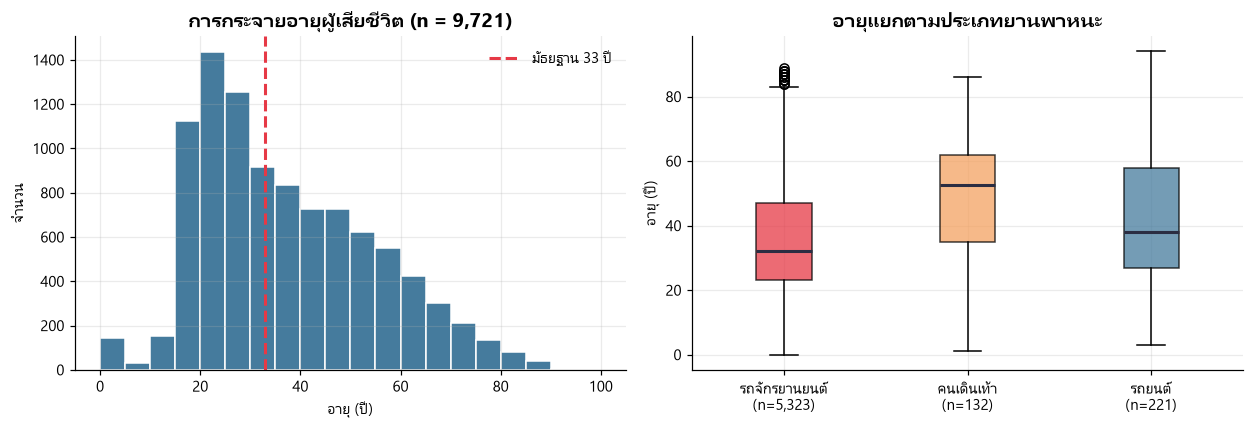

อายุ: มัธยฐาน 33 ปี | เฉลี่ย 36.8 ปี | ควอไทล์ที่ 1-3 = 23–49 ปี
เพศชาย: 81.6% ของรายที่ระบุเพศได้ (ช่วงความเชื่อมั่น 95% 80.9%–82.3%)
  รถจักรยานยนต์  มัธยฐาน 32 ปี
  คนเดินเท้า     มัธยฐาน 52 ปี
  รถยนต์         มัธยฐาน 38 ปี


In [10]:
age = df["age_clean"].dropna()
male_known = df[df["sex_known"]]
male_share = (male_known["sex"] == "ชาย").mean()
mlo, mhi = stats.binomtest((male_known["sex"] == "ชาย").sum(), len(male_known)).proportion_ci()

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))

ax = axes[0]
ax.hist(age, bins=np.arange(0, 105, 5), color="#457b9d", edgecolor="white")
ax.axvline(age.median(), color=ACCENT, lw=2, ls="--", label=f"มัธยฐาน {age.median():.0f} ปี")
ax.set_title(f"การกระจายอายุผู้เสียชีวิต (n = {len(age):,})")
ax.set_xlabel("อายุ (ปี)")
ax.set_ylabel("จำนวน")
ax.legend(frameon=False)

ax = axes[1]
groups = ["รถจักรยานยนต์", "คนเดินเท้า", "รถยนต์"]
data = [df.loc[df["vehicle"] == g, "age_clean"].dropna() for g in groups]
bp = ax.boxplot(data, tick_labels=[f"{g}\n(n={len(d):,})" for g, d in zip(groups, data)],
                patch_artist=True, medianprops=dict(color=INK, lw=2))
for patch, color in zip(bp["boxes"], [ACCENT, "#f4a261", "#457b9d"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
ax.set_title("อายุแยกตามประเภทยานพาหนะ")
ax.set_ylabel("อายุ (ปี)")
plt.show()

print(f"อายุ: มัธยฐาน {age.median():.0f} ปี | เฉลี่ย {age.mean():.1f} ปี | ควอไทล์ที่ 1-3 = "
      f"{age.quantile(.25):.0f}–{age.quantile(.75):.0f} ปี")
print(f"เพศชาย: {male_share:.1%} ของรายที่ระบุเพศได้ (ช่วงความเชื่อมั่น 95% {mlo:.1%}–{mhi:.1%})")
for g, d in zip(groups, data):
    print(f"  {g:14s} มัธยฐาน {d.median():.0f} ปี")

ภาพที่ได้คือ **ชายวัยทำงานตอนต้น** ผู้เสียชีวิตเป็นชาย 82% และอายุมัธยฐานอยู่ที่ 33 ปี
ซึ่งเป็นช่วงวัยที่กำลังหารายได้หลักให้ครอบครัว ต้นทุนทางเศรษฐกิจของการสูญเสียจึงสูงกว่า
ที่ตัวเลขผู้เสียชีวิตเพียงอย่างเดียวจะบอกได้

กราฟขวาชี้จุดที่ควรแยกมาตรการ — **คนเดินเท้าที่เสียชีวิตมีอายุมากกว่ากลุ่มอื่นอย่างเห็นได้ชัด**
ปัญหาของคนกลุ่มนี้คนละเรื่องกับผู้ขับขี่มอเตอร์ไซค์ เกี่ยวกับทางข้าม ความเร็วรถในย่านชุมชน
และเวลาที่ไฟคนข้ามให้ ซึ่งผู้สูงอายุต้องการมากกว่าที่ออกแบบไว้

## 7. คำถามที่ 4 — เกิดเหตุเวลาไหน

ส่วนนี้ใช้ได้เฉพาะแถวที่มีเวลาบันทึก (ราวครึ่งหนึ่งของข้อมูล) จึงต้องถือว่าเป็นภาพของกลุ่มย่อย
ไม่ใช่ของทั้งหมด

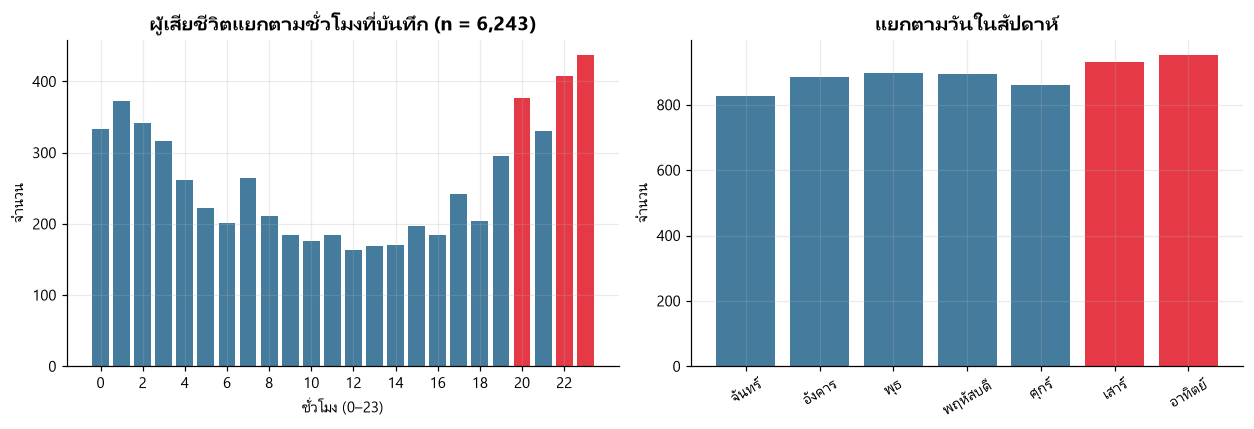

ช่วงกลางคืน 20:00–04:59 : 3,176 ราย = 50.9% ของรายที่มีเวลา (ช่วงเวลานี้กินเวลา 38% ของวัน)
เฉลี่ยต่อวันธรรมดา     : 872 ราย
เฉลี่ยต่อวันเสาร์–อาทิตย์ : 941 ราย  (+7.9%)


In [11]:
timed = df[df["hour"].notna()].copy()
by_hour = timed.groupby("hour").size()
DOW_TH = ["จันทร์", "อังคาร", "พุธ", "พฤหัสบดี", "ศุกร์", "เสาร์", "อาทิตย์"]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))

ax = axes[0]
peak_hours = by_hour.nlargest(3).index
ax.bar(by_hour.index, by_hour.values,
       color=[ACCENT if h in peak_hours else "#457b9d" for h in by_hour.index])
ax.set_title(f"ผู้เสียชีวิตแยกตามชั่วโมงที่บันทึก (n = {len(timed):,})")
ax.set_xlabel("ชั่วโมง (0–23)")
ax.set_ylabel("จำนวน")
ax.set_xticks(range(0, 24, 2))

ax = axes[1]
by_dow = timed.groupby("dow").size()
ax.bar([DOW_TH[i] for i in by_dow.index], by_dow.values,
       color=["#457b9d"] * 5 + [ACCENT] * 2)
ax.set_title("แยกตามวันในสัปดาห์")
ax.set_ylabel("จำนวน")
ax.tick_params(axis="x", rotation=30)
plt.show()

night = by_hour.loc[[h for h in range(24) if h >= 20 or h <= 4]].sum()
print(f"ช่วงกลางคืน 20:00–04:59 : {night:,} ราย = {night/by_hour.sum():.1%} ของรายที่มีเวลา "
      f"(ช่วงเวลานี้กินเวลา {9/24:.0%} ของวัน)")
weekday_avg, weekend_avg = by_dow.loc[:4].mean(), by_dow.loc[5:].mean()
print(f"เฉลี่ยต่อวันธรรมดา     : {weekday_avg:,.0f} ราย")
print(f"เฉลี่ยต่อวันเสาร์–อาทิตย์ : {weekend_avg:,.0f} ราย  ({weekend_avg/weekday_avg - 1:+.1%})")

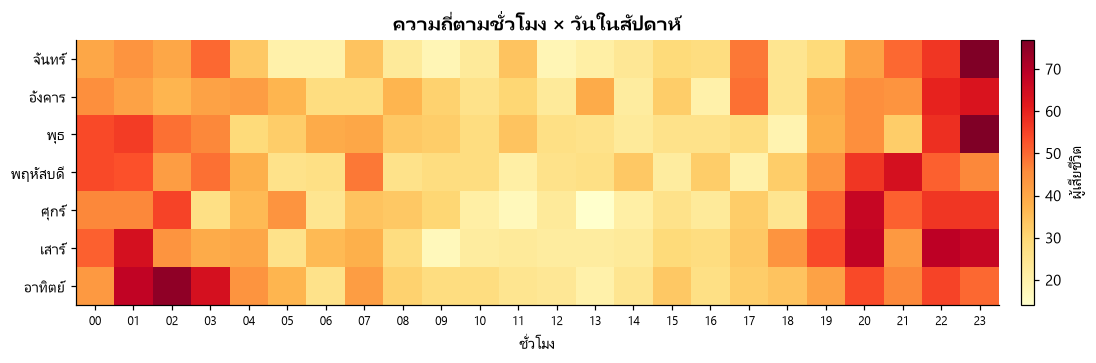

ช่องที่หนาแน่นที่สุด: จันทร์ เวลา 23:00 น. (77 ราย)


In [12]:
pivot = timed.pivot_table(index="dow", columns="hour", values="year", aggfunc="count").fillna(0)
pivot = pivot.reindex(columns=range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(pivot.values, aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(7), DOW_TH)
ax.set_xticks(range(0, 24, 1), [f"{h:02d}" for h in range(24)], fontsize=8)
ax.set_xlabel("ชั่วโมง")
ax.set_title("ความถี่ตามชั่วโมง × วันในสัปดาห์")
ax.grid(False)
fig.colorbar(im, ax=ax, label="ผู้เสียชีวิต", pad=0.02)
plt.show()

hottest = np.unravel_index(np.argmax(pivot.values), pivot.shape)
print(f"ช่องที่หนาแน่นที่สุด: {DOW_TH[hottest[0]]} เวลา {pivot.columns[hottest[1]]:02d}:00 น. "
      f"({int(pivot.values[hottest]):,} ราย)")

**กลางคืนคือช่วงที่อันตรายจริง** ช่วงสองทุ่มถึงตีห้ากินเวลา 38% ของวัน
แต่มีผู้เสียชีวิตถึง 51% ของรายที่มีเวลาบันทึก คิดเป็นความเสี่ยงต่อหน่วยเวลาราว 1.3 เท่าของช่วงกลางวัน

**ส่วนสุดสัปดาห์ต่างจากที่คาดไว้** ถ้าดูแค่สัดส่วนรวมจะเห็น 30% ซึ่งใกล้เคียงกับ 29% ที่ควรเป็น
และดูเหมือนไม่ต่าง แต่การเทียบแบบนั้นผิด เพราะเสาร์อาทิตย์มีแค่ 2 ใน 7 วัน
เมื่อเทียบ**ค่าเฉลี่ยต่อวัน**จึงเห็นว่าสูงกว่าวันธรรมดาราว 8% ซึ่งมีอยู่จริงแต่เป็นผลที่เล็กกว่าที่คาด
และเล็กกว่าผลของช่วงเวลากลางคืนมาก

ข้อสังเกตที่ต้องระวังในการตีความ: คอลัมน์นี้คือ**เวลาที่บันทึก** ซึ่งอาจเป็นเวลาที่เสียชีวิตหรือ
เวลาที่รับแจ้ง ไม่ใช่เวลาที่เกิดเหตุเสมอไป รูปแบบกลางคืนจึงอาจถูกขยายจากความล่าช้าในการส่งถึงโรงพยาบาล
แต่ทิศทางโดยรวมยังสอดคล้องกับงานวิจัยความปลอดภัยทางถนนทั่วไปที่พบว่าเวลากลางคืนเสี่ยงกว่า
จากทัศนวิสัย ความเร็ว และการดื่มแอลกอฮอล์

## 8. คำถามที่ 5 — กระจุกตัวที่ไหน

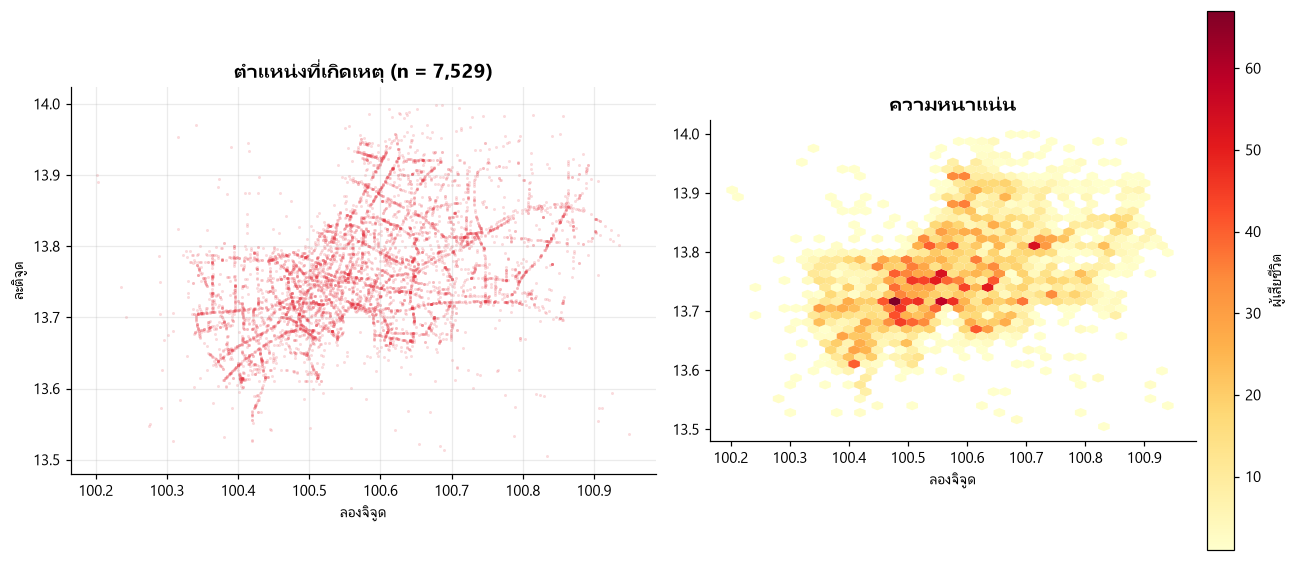

ช่องตารางที่มีข้อมูล 685 ช่อง
ช่องที่หนาแน่นสุดมี 67 ราย
ช่องที่หนาแน่นสุด 10% แรก รวมกันคิดเป็น 33% ของผู้เสียชีวิตที่มีพิกัด


In [13]:
geo = df.dropna(subset=["lat_clean", "lng_clean"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))

ax = axes[0]
ax.scatter(geo["lng_clean"], geo["lat_clean"], s=4, alpha=0.18, color=ACCENT, linewidths=0)
ax.set_title(f"ตำแหน่งที่เกิดเหตุ (n = {len(geo):,})")
ax.set_xlabel("ลองจิจูด")
ax.set_ylabel("ละติจูด")
ax.set_aspect("equal", adjustable="box")

ax = axes[1]
hb = ax.hexbin(geo["lng_clean"], geo["lat_clean"], gridsize=38, cmap="YlOrRd", mincnt=1, linewidths=0)
ax.set_title("ความหนาแน่น")
ax.set_xlabel("ลองจิจูด")
ax.set_aspect("equal", adjustable="box")
ax.grid(False)
fig.colorbar(hb, ax=ax, label="ผู้เสียชีวิต", pad=0.02)
plt.show()

counts = hb.get_array()
print(f"ช่องตารางที่มีข้อมูล {(counts > 0).sum():,} ช่อง")
print(f"ช่องที่หนาแน่นสุดมี {int(counts.max())} ราย")
share_top = np.sort(counts)[::-1][: max(1, int((counts > 0).sum() * 0.1))].sum() / counts.sum()
print(f"ช่องที่หนาแน่นสุด 10% แรก รวมกันคิดเป็น {share_top:.0%} ของผู้เสียชีวิตที่มีพิกัด")

**การเสียชีวิตกระจุกตัวชัดเจน** พื้นที่เพียงหนึ่งในสิบของบริเวณที่เคยเกิดเหตุ
รองรับผู้เสียชีวิตถึงหนึ่งในสาม — สูงกว่าการกระจายแบบสม่ำเสมอกว่าสามเท่า

นี่คือข้อค้นพบที่มีประโยชน์ที่สุดในเชิงปฏิบัติ เพราะแปลว่างบประมาณความปลอดภัยทางถนนที่มีจำกัด
ไม่ควรโรยทั่วเมือง แต่ควรทุ่มไปที่จุดที่เกิดเหตุซ้ำ ๆ ซึ่งระบุตำแหน่งได้จากข้อมูลชุดนี้

**ข้อจำกัดที่ต้องพูดให้ชัด** — จุดที่พล็อตได้มาจาก 63% ของข้อมูลที่มีพิกัด ถ้าการบันทึกพิกัดเกิดขึ้น
บ่อยกว่าในบางพื้นที่ (เช่น เขตที่มีระบบรับแจ้งเหตุดีกว่า) แผนที่นี้จะสะท้อนความสามารถในการบันทึก
ปนกับความเสี่ยงจริง และเนื่องจากยังไม่ได้หารด้วยปริมาณการจราจรหรือจำนวนประชากร
จุดที่แดงจึงหมายถึง "มีคนตายมาก" ไม่ใช่ "อันตรายที่สุดต่อการเดินทางหนึ่งเที่ยว" ซึ่งเป็นคนละคำถาม

## 9. สรุปผลเป็นตัวเลข

In [14]:
yearly = complete.groupby("year_th").size()
known = df[df["vehicle_known"]]
moto = (known["vehicle"] == "รถจักรยานยนต์").mean()
age = df["age_clean"].dropna()
male = (df.loc[df["sex_known"], "sex"] == "ชาย").mean()
geo = df.dropna(subset=["lat_clean", "lng_clean"])

print("ข้อค้นพบหลัก")
print("=" * 58)
print(f"ช่วงข้อมูล              {df['year_th'].min()}–{df['year_th'].max()} พ.ศ. ({len(df):,} ราย)")
print(f"ปีที่ใช้ดูแนวโน้มได้      {yearly.index.min()}–{yearly.index.max()} ({len(yearly)} ปี)")
print(f"เฉลี่ยต่อปี             {yearly.mean():.0f} ราย  (~{yearly.mean()/365:.1f} รายต่อวัน)")
print(f"สูงสุด / ต่ำสุด         {yearly.max()} ({yearly.idxmax()}) / {yearly.min()} ({yearly.idxmin()})")
print(f"มอเตอร์ไซค์             {moto:.1%} ของรายที่ระบุพาหนะได้ (n = {len(known):,})")
print(f"เพศชาย                 {male:.1%}")
print(f"อายุมัธยฐาน             {age.median():.0f} ปี")
print(f"มีพิกัดใช้งานได้         {len(geo):,} ราย ({len(geo)/len(df):.0%})")
print("=" * 58)
print()
print("ข้อจำกัดที่ต้องระบุทุกครั้งที่อ้างอิงตัวเลขข้างบน")
print(f"  - ไม่ระบุประเภทพาหนะ {1 - df['vehicle_known'].mean():.0%} และการกรอกแย่ลงตามปี")
print(f"  - ไม่มีอายุ {df['age_clean'].isna().mean():.0%} ของแถว")
print(f"  - ไม่มีเวลาเกิดเหตุ {df['hour'].isna().mean():.0%} ของแถว")
print(f"  - หมวกกันน็อกและเข็มขัดนิรภัยว่าง 100% ใช้ไม่ได้เลย")
print(f"  - ปี 2568–2569 ข้อมูลยังเข้าไม่ครบ ถูกตัดออกจากการวิเคราะห์แนวโน้ม")

ข้อค้นพบหลัก
ช่วงข้อมูล              2554–2569 พ.ศ. (12,146 ราย)
ปีที่ใช้ดูแนวโน้มได้      2554–2567 (14 ปี)
เฉลี่ยต่อปี             822 ราย  (~2.3 รายต่อวัน)
สูงสุด / ต่ำสุด         893 (2562) / 675 (2567)
มอเตอร์ไซค์             92.5% ของรายที่ระบุพาหนะได้ (n = 5,818)
เพศชาย                 81.6%
อายุมัธยฐาน             33 ปี
มีพิกัดใช้งานได้         7,529 ราย (62%)

ข้อจำกัดที่ต้องระบุทุกครั้งที่อ้างอิงตัวเลขข้างบน
  - ไม่ระบุประเภทพาหนะ 52% และการกรอกแย่ลงตามปี
  - ไม่มีอายุ 20% ของแถว
  - ไม่มีเวลาเกิดเหตุ 49% ของแถว
  - หมวกกันน็อกและเข็มขัดนิรภัยว่าง 100% ใช้ไม่ได้เลย
  - ปี 2568–2569 ข้อมูลยังเข้าไม่ครบ ถูกตัดออกจากการวิเคราะห์แนวโน้ม


## 10. สิ่งที่สรุปได้ และสิ่งที่ยังสรุปไม่ได้

**สรุปได้จากข้อมูลชุดนี้**

1. ผู้เสียชีวิตบนถนนในกรุงเทพฯ อยู่ที่เฉลี่ย 822 รายต่อปีมาตลอด 14 ปี เส้นแนวโน้มลาดลงเล็กน้อย
   แต่ยังไม่มีนัยสำคัญทางสถิติ (p = 0.15) และไม่พบการลดลงในช่วงโควิดอย่างที่หลายประเทศพบ
2. ผู้เสียชีวิตที่ระบุพาหนะได้เป็นผู้ใช้มอเตอร์ไซค์ราว 92% — มาตรการใดที่ไม่แตะกลุ่มนี้
   แทบไม่มีผลต่อตัวเลขรวม
3. กลุ่มเสี่ยงหลักคือชายอายุราว 33 ปี ส่วนคนเดินเท้าที่เสียชีวิตเป็นคนละกลุ่มและอายุมากกว่า
   ต้องใช้มาตรการคนละแบบ
4. ความเสี่ยงกระจุกทั้งเชิงเวลาและเชิงพื้นที่ — กลางคืนเสี่ยงกว่ากลางวันราว 1.3 เท่าต่อหน่วยเวลา
   และพื้นที่เพียง 10% รองรับผู้เสียชีวิต 33% มาตรการแบบเจาะจงจุดจึงน่าจะคุ้มกว่าการทำทั่วเมือง
   ส่วนผลของวันสุดสัปดาห์มีอยู่จริงแต่เล็ก (+8% ต่อวัน)

**ยังสรุปไม่ได้ ต้องมีข้อมูลเพิ่ม**

| คำถาม | สิ่งที่ขาด |
| --- | --- |
| เขตไหน "อันตรายที่สุด" จริง ๆ | จำนวนประชากรและปริมาณการจราจรรายเขต เพื่อใช้เป็นตัวหาร |
| หมวกกันน็อกช่วยได้แค่ไหน | คอลัมน์ที่มีอยู่ว่างทั้งหมด ต้องหาแหล่งข้อมูลอื่น |
| จุดเสี่ยงเกิดจากการออกแบบถนนหรือไม่ | ข้อมูลกายภาพของถนน เช่น ทางแยก ทางข้าม ไฟส่องสว่าง จำนวนช่องจราจร |
| ปี 2567 ที่ต่ำสุดในรอบ 14 ปี คือขาลงจริงไหม | ต้องรอข้อมูลปี 2568–2569 เข้าครบ ซึ่งล่าช้าราว 7–8 เดือน |
| ทำไมโควิดไม่ทำให้ตัวเลขลด | ปริมาณการจราจรรายปี เพื่อคำนวณอัตราต่อระยะทางเดินทาง |

**สิ่งที่ทำต่อได้**

- จับคู่พิกัดกับขอบเขตเขตการปกครองเพื่อคำนวณอัตราต่อประชากรแสนคน
- ทดสอบทางสถิติว่าการกระจุกตัวเชิงพื้นที่ต่างจากการสุ่มอย่างมีนัยสำคัญหรือไม่ (Ripley's K)
- รวมข้อมูลหลายจังหวัดเพื่อเทียบกรุงเทพฯ กับเมืองอื่น

---

**ที่มาข้อมูล** ระบบบูรณาการข้อมูลการตายจากอุบัติเหตุทางถนน (3 ฐาน) กรมควบคุมโรค กระทรวงสาธารณสุข
เผยแพร่ผ่าน data.go.th ภายใต้เงื่อนไขข้อมูลเปิดภาครัฐ · ดึงข้อมูลด้วย `analysis/fetch_data.py`